In [3]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
X, y = digits.data, digits.target
print(X.shape, y.shape)
print(X[0])

(1797, 64) (1797,)
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


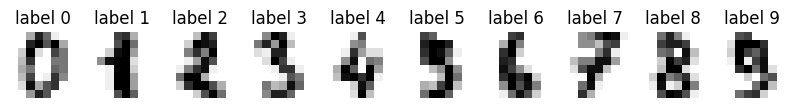

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(10, 2.5))
for ax, img, label in zip(axes, digits.images[:10], y[:10]):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f"label {label}")
    ax.axis('off')
plt.show()    

In [5]:
import sys
sys.path.append("../src")
from pca import PCA

X_test = np.array([[2, 1], [1, 2], [-1, -2], [-2, -1]], dtype=float)
p = PCA(n_components=1).fit(X_test)
print(p.explained_variance_)
print(p.components_)

y = p.transform(X_test)
x_b = p.inverse_transform(y)
print(x_b)

[6.]
[[0.70710678]
 [0.70710678]]
[[ 1.5  1.5]
 [ 1.5  1.5]
 [-1.5 -1.5]
 [-1.5 -1.5]]


In [6]:
p = PCA(n_components=1).fit(X_test)
print(p.transform(X_test))
print(p.explained_variance_ratio_)

[[ 2.12132034]
 [ 2.12132034]
 [-2.12132034]
 [-2.12132034]]
[0.9]


In [7]:
from sklearn.decomposition import PCA as SkPCA

mine = PCA(n_components=10)
Z_mine = mine.fit_transform(X)

sk = SkPCA(n_components=10)
Z_sk = sk.fit_transform(X)

print(Z_mine.shape, Z_sk.shape)
print(np.allclose(mine.explained_variance_, sk.explained_variance_))
print(np.allclose(mine.explained_variance_ratio_, sk.explained_variance_ratio_))
print(np.allclose(np.abs(Z_mine), np.abs(Z_sk)))
print(np.allclose(np.abs(mine.components_.T), np.abs(sk.components_)))

(1797, 10) (1797, 10)
True
True
True
True


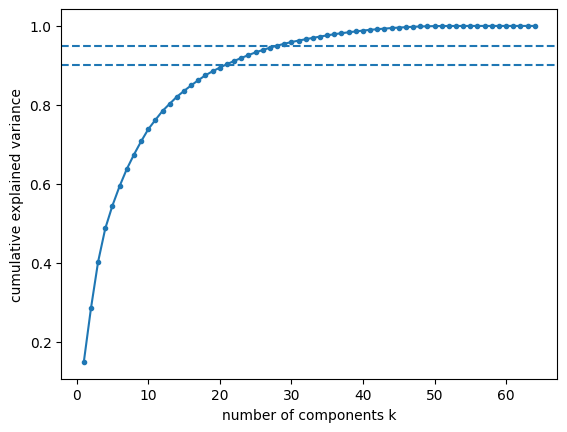

21 29


In [8]:
full = PCA(n_components=64).fit(X)
cum = np.cumsum(full.explained_variance_ratio_)

plt.plot(range(1, 65), cum, marker="o", markersize=3)
plt.axhline(0.90, linestyle="--")
plt.axhline(0.95, linestyle="--")
plt.xlabel("number of components k")
plt.ylabel("cumulative explained variance")
plt.show()

k90 = np.argmax(cum >= 0.90) + 1
k95 = np.argmax(cum >= 0.95) + 1
print(k90, k95)

(1797, 64) (1797, 21) (1797, 64)


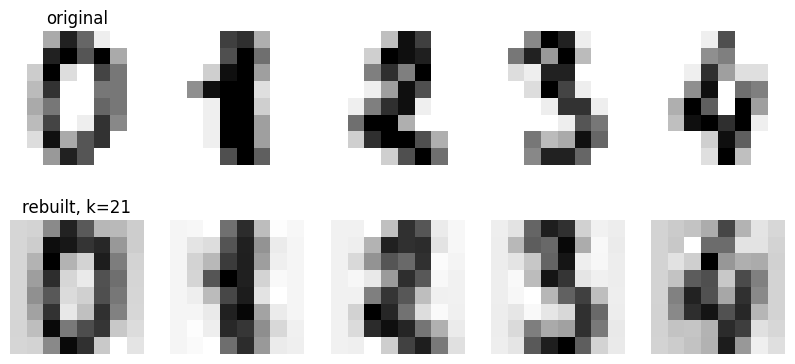

In [19]:
pca21 = PCA(n_components=21).fit(X)
y = pca21.transform(X)
X_back = pca21.inverse_transform(y)
print(X.shape, y.shape, X_back.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i in range(5):
    axes[0, i].imshow(X[i].reshape(8, 8), cmap='gray_r')
    axes[1, i].imshow(X_back[i].reshape(8, 8), cmap='gray_r')
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("original")
axes[1, 0].set_title("rebuilt, k=21")

plt.savefig("../images/rebuilt_digits_k21.png", dpi=150, bbox_inches="tight")
plt.show()

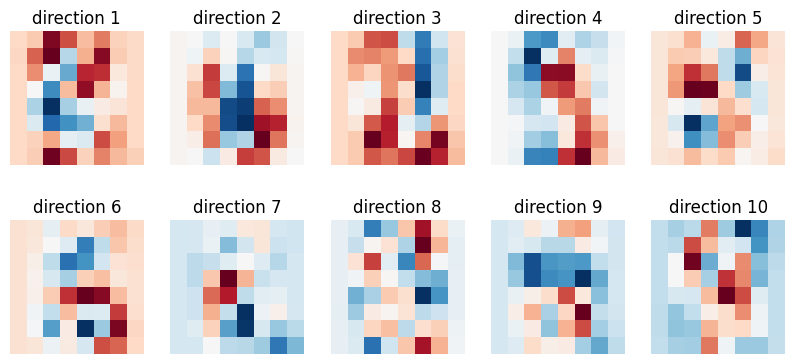

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca21.components_[:, i].reshape(8, 8), cmap="RdBu")
    ax.set_title(f"direction {i+1}")
    ax.axis("off")
plt.show()

In [11]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0,stratify=y
)
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)
print(X_train.shape, X_test.shape)
print(model.score(X_test, y_test))


(1437, 64) (360, 64)
0.9583333333333334


In [12]:
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from pca import PCA

digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

accu = set()

for k in [2, 5, 10, 21, 29, 40, 64]:
    pca = PCA(n_components=k)

    z_train = pca.fit_transform(X_train)
    z_test = pca.transform(X_test)

    clf = LogisticRegression(max_iter=5000)
    clf.fit(z_train, y_train)
    
    accu.add((k,clf.score(z_test, y_test)))

    print(k, round(clf.score(z_test, y_test),3))
print(accu)    
    

2 0.592
5 0.844
10 0.931
21 0.942
29 0.958
40 0.958
64 0.958
{(2, 0.5916666666666667), (10, 0.9305555555555556), (29, 0.9583333333333334), (40, 0.9583333333333334), (64, 0.9583333333333334), (5, 0.8444444444444444), (21, 0.9416666666666667)}


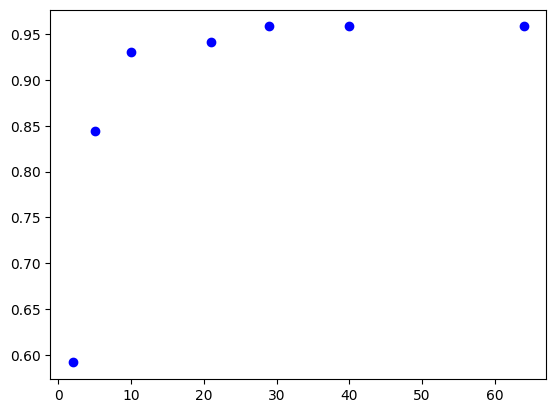

In [13]:
x_values = [pt[0] for pt in accu]
y_values = [pt[1] for pt in accu]

plt.plot(x_values, y_values, 'bo')


In [14]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
ks = [2, 5, 10, 21, 29, 40, 64]
results = {k: [] for k in ks}
baseline = []

for tr_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]

    base = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
    baseline.append(base.score(X_val, y_val))

    for k in ks:
        pca = PCA(n_components=k)
        Z_tr = pca.fit_transform(X_tr)
        Z_val = pca.transform(X_val)
        clf = LogisticRegression(max_iter=5000).fit(Z_tr, y_tr)
        results[k].append(clf.score(Z_val, y_val))

print("no PCA", round(np.mean(baseline), 3), round(np.std(baseline), 3))
for k in ks:
    print(k, round(np.mean(results[k]), 3), round(np.std(results[k]), 3))

no PCA 0.962 0.012
2 0.618 0.012
5 0.852 0.018
10 0.925 0.012
21 0.945 0.014
29 0.955 0.008
40 0.963 0.01
64 0.965 0.008


In [15]:
pca = PCA(n_components=29)
z_train = pca.fit_transform(X_train)
z_test = pca.transform(X_test)

clf = LogisticRegression(max_iter=5000).fit(z_train, y_train)
print(clf.score(z_test, y_test))

0.9583333333333334


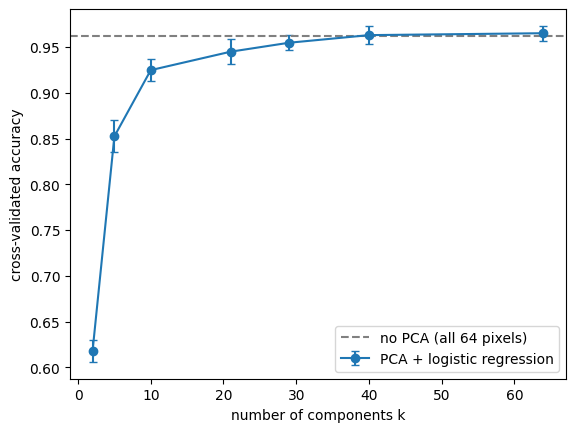

In [17]:
means = [np.mean(results[k]) for k in ks]
stds = [np.std(results[k]) for k in ks]

plt.errorbar(ks, means, yerr=stds, marker='o', capsize=3, label='PCA + logistic regression')

plt.axhline(np.mean(baseline), linestyle="--", color="gray",
            label="no PCA (all 64 pixels)")
plt.xlabel("number of components k")
plt.ylabel("cross-validated accuracy")
plt.legend()
plt.savefig("../images/accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()


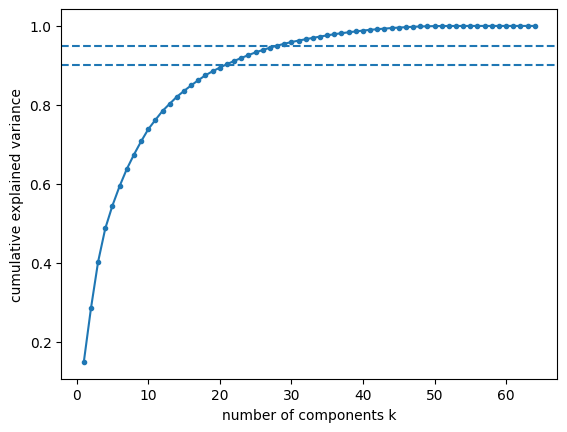

In [18]:
full = PCA(n_components=64).fit(X)
cum = np.cumsum(full.explained_variance_ratio_)

plt.plot(range(1, 65), cum, marker="o", markersize=3)
plt.axhline(0.90, linestyle="--")
plt.axhline(0.95, linestyle="--")
plt.xlabel("number of components k")
plt.ylabel("cumulative explained variance")
plt.savefig("../images/explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()